# Homework 5

Name: Shanglin Jiang

GitHub Username: sjiang83-corgi

USC ID: 1967702034

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from threadpoolctl import threadpool_limits
from xgboost import XGBRegressor

SEED = 552
DATA_DIR = Path("../data")
RESULT_DIR = Path("../results")
RESULT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_rows", 150)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 6)
plt.rcParams["figure.dpi"] = 110

## 1(a) Acute Inflammations data

I used label powerset to combine the two diagnoses into four classes.

In [2]:
diagnosis_columns = [
    "temperature", "nausea", "lumbar_pain", "urine_pushing",
    "micturition_pain", "urethra_burning", "bladder_inflammation", "nephritis"
]
diagnosis = pd.read_csv(
    DATA_DIR / "diagnosis.data", sep="\t", encoding="utf-16",
    decimal=",", header=None, names=diagnosis_columns
)
for column in diagnosis_columns[1:]:
    diagnosis[column] = diagnosis[column].map({"no": 0, "yes": 1})

assert diagnosis.shape == (120, 8)
assert not diagnosis.isna().any().any()
X_diagnosis = diagnosis.iloc[:, :6]
y_diagnosis = 2 * diagnosis["bladder_inflammation"] + diagnosis["nephritis"]
class_names = ["Neither", "Nephritis only", "Bladder only", "Both"]
display(diagnosis.head())
display(y_diagnosis.value_counts().sort_index().rename(index=dict(enumerate(class_names))))

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Neither           30
Nephritis only    31
Bladder only      40
Both              19
Name: count, dtype: int64

## 1(b) Decision tree on the full data set

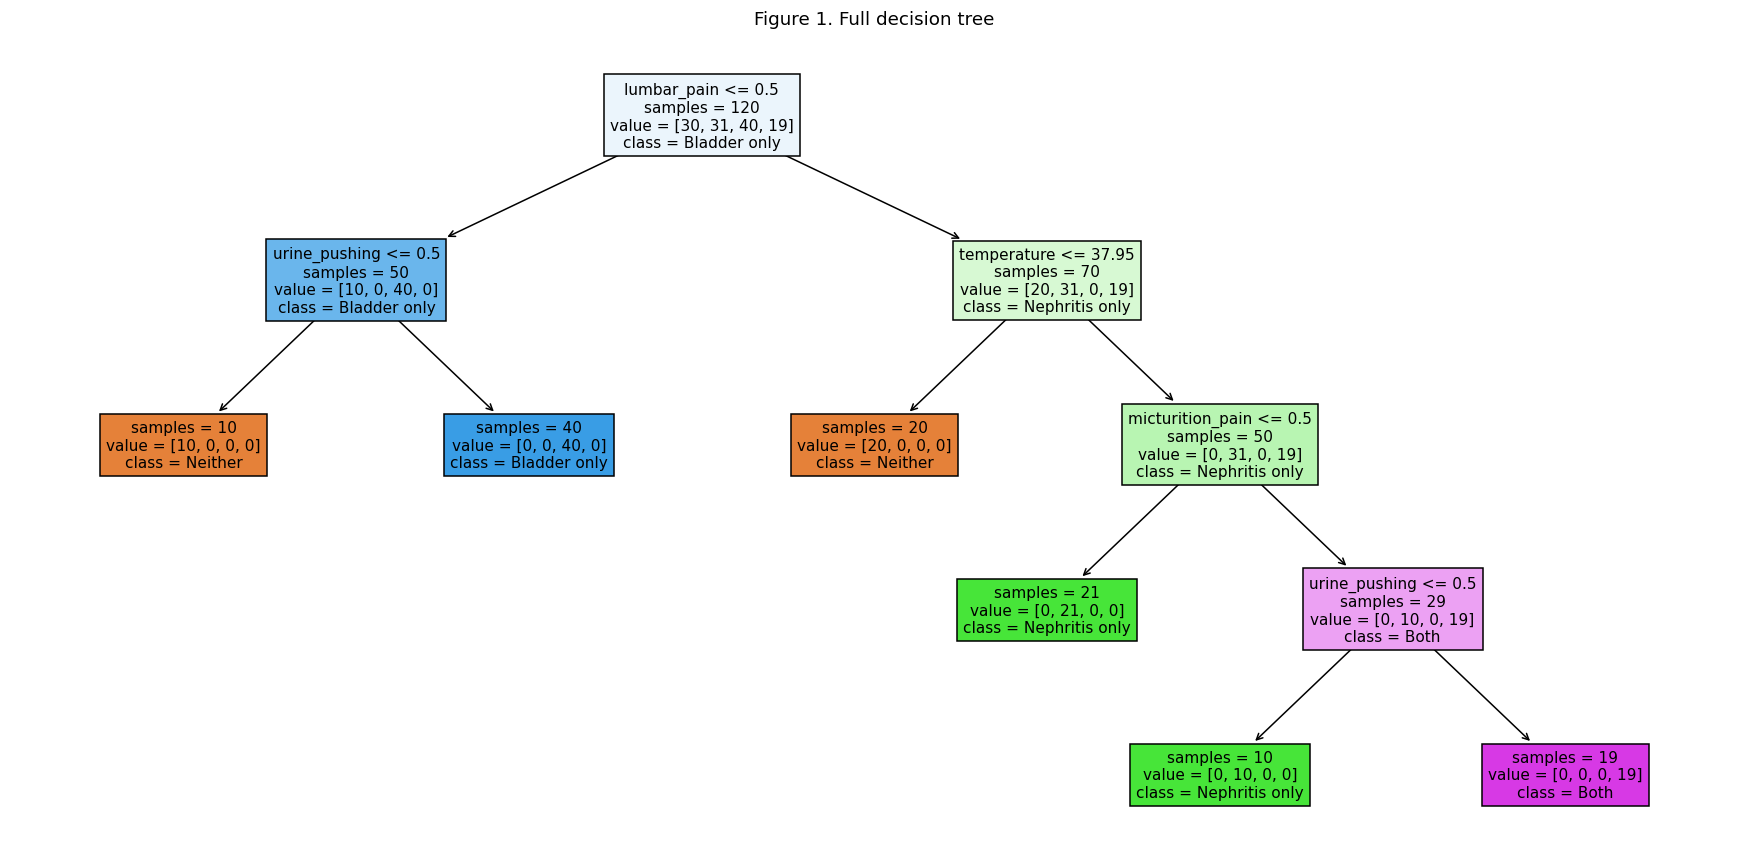

Leaves: 6
Depth: 4
Training accuracy: 1.0


In [3]:
full_tree = DecisionTreeClassifier(random_state=SEED)
full_tree.fit(X_diagnosis, y_diagnosis)

def draw_tree(model, title, filename):
    fig, ax = plt.subplots(figsize=(16, 8))
    plot_tree(
        model, feature_names=X_diagnosis.columns.tolist(),
        class_names=class_names, filled=True, rounded=False,
        impurity=False, fontsize=10, ax=ax
    )
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(RESULT_DIR / filename, bbox_inches="tight")
    plt.show()

draw_tree(full_tree, "Figure 1. Full decision tree", "full_tree.png")
print("Leaves:", full_tree.get_n_leaves())
print("Depth:", full_tree.get_depth())
print("Training accuracy:", full_tree.score(X_diagnosis, y_diagnosis))

## 1(c) IF-THEN rules

In [4]:
def extract_rules(model):
    tree = model.tree_
    rules = []

    def visit(node, conditions):
        if tree.children_left[node] == tree.children_right[node]:
            class_index = np.argmax(tree.value[node][0])
            label = class_names[int(model.classes_[class_index])]
            condition = " AND ".join(conditions) if conditions else "TRUE"
            rules.append({
                "Rule": f"IF {condition} THEN {label}",
                "Samples": tree.n_node_samples[node]
            })
            return

        feature = X_diagnosis.columns[tree.feature[node]]
        threshold = tree.threshold[node]
        if feature == "temperature":
            left = f"{feature} <= {threshold:.2f}"
            right = f"{feature} > {threshold:.2f}"
        else:
            left = f"{feature} = no"
            right = f"{feature} = yes"
        visit(tree.children_left[node], conditions + [left])
        visit(tree.children_right[node], conditions + [right])

    visit(0, [])
    return pd.DataFrame(rules)

full_rules = extract_rules(full_tree)
for rule in full_rules["Rule"]:
    print(rule)
full_rules.to_csv(RESULT_DIR / "full_tree_rules.csv", index=False)

IF lumbar_pain = no AND urine_pushing = no THEN Neither
IF lumbar_pain = no AND urine_pushing = yes THEN Bladder only
IF lumbar_pain = yes AND temperature <= 37.95 THEN Neither
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pain = no THEN Nephritis only
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pain = yes AND urine_pushing = no THEN Nephritis only
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pain = yes AND urine_pushing = yes THEN Both


## 1(d) Cost-complexity pruning

I chose the smallest subtree along the pruning path that still classified at least 80% of the training cases correctly on both diagnoses.

,alpha,leaves,depth,training_accuracy
0,0.000000,6,4,1.000000
1,0.098167,4,2,0.841667
2,0.133333,3,2,0.758333
3,0.182000,2,1,0.591667
4,0.222917,1,0,0.333333


,alpha,leaves,depth,training_accuracy
1,0.098167,4,2,0.841667


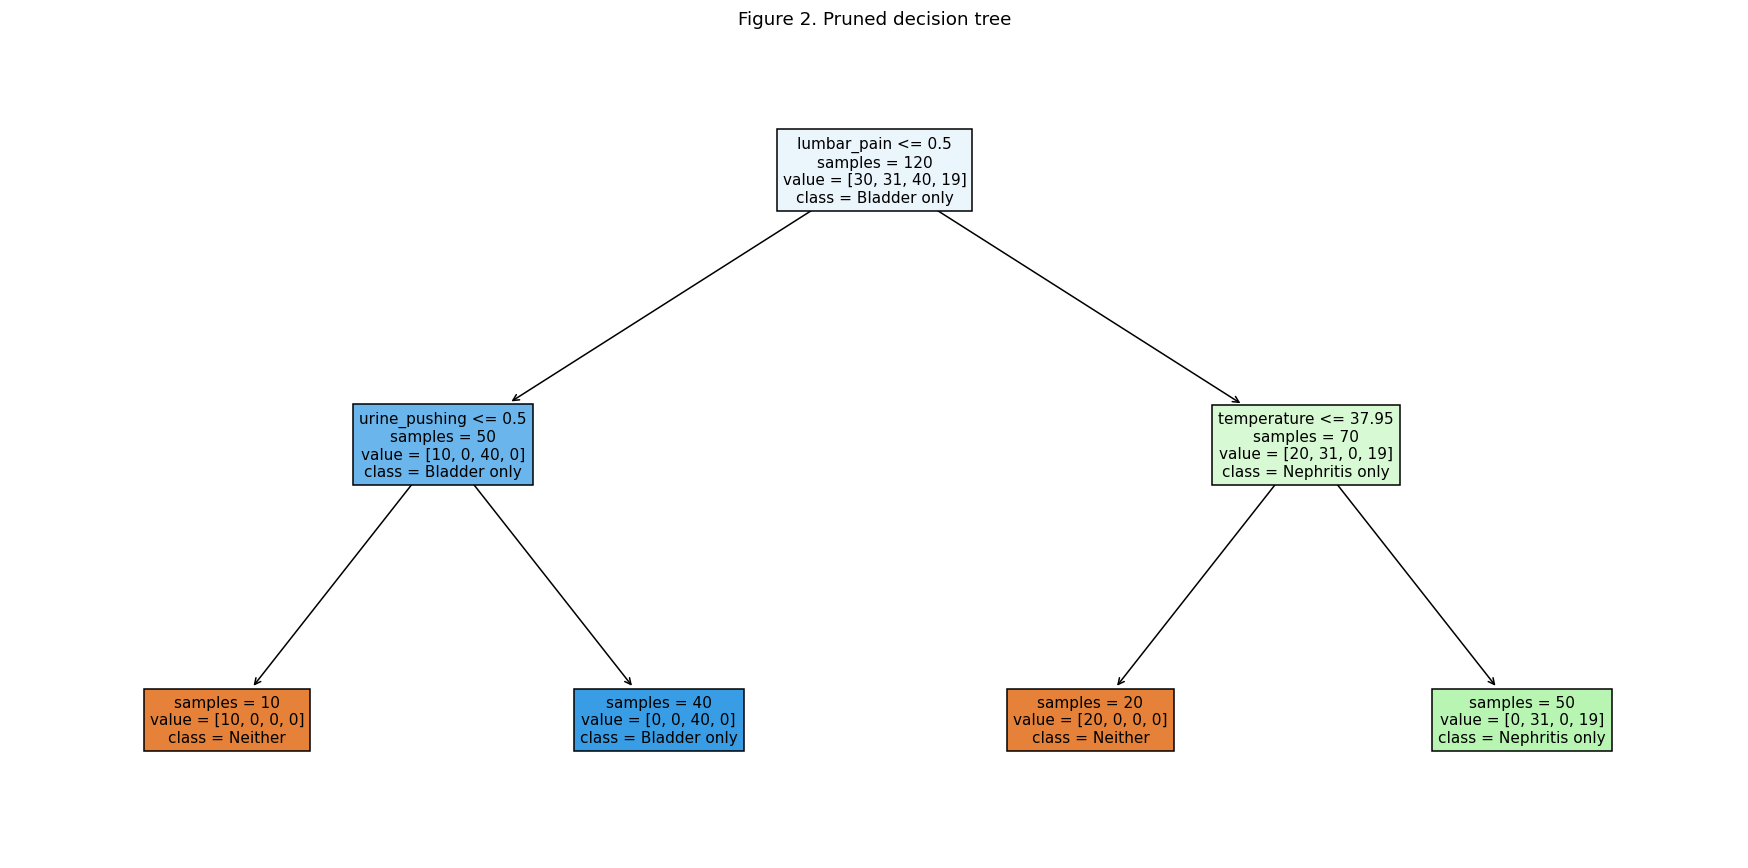

IF lumbar_pain = no AND urine_pushing = no THEN Neither
IF lumbar_pain = no AND urine_pushing = yes THEN Bladder only
IF lumbar_pain = yes AND temperature <= 37.95 THEN Neither
IF lumbar_pain = yes AND temperature > 37.95 THEN Nephritis only


In [5]:
path = full_tree.cost_complexity_pruning_path(X_diagnosis, y_diagnosis)
pruning_rows = []
pruned_models = []
for alpha in path.ccp_alphas:
    model = DecisionTreeClassifier(ccp_alpha=float(alpha), random_state=SEED)
    model.fit(X_diagnosis, y_diagnosis)
    pruned_models.append(model)
    pruning_rows.append({
        "alpha": alpha,
        "leaves": model.get_n_leaves(),
        "depth": model.get_depth(),
        "training_accuracy": model.score(X_diagnosis, y_diagnosis)
    })

pruning_results = pd.DataFrame(pruning_rows)
display(pruning_results)
eligible = pruning_results[pruning_results["training_accuracy"] >= 0.80]
chosen_index = eligible.sort_values(["leaves", "alpha"]).index[0]
pruned_tree = pruned_models[chosen_index]
display(pruning_results.loc[[chosen_index]])
draw_tree(pruned_tree, "Figure 2. Pruned decision tree", "pruned_tree.png")
pruned_rules = extract_rules(pruned_tree)
for rule in pruned_rules["Rule"]:
    print(rule)
pruned_rules.to_csv(RESULT_DIR / "pruned_tree_rules.csv", index=False)
pruning_results.to_csv(RESULT_DIR / "pruning_path.csv", index=False)

With alpha = 0.098167, the tree goes from 6 leaves to 4, and its depth drops from 4 to 2. Training accuracy drops from 100% to 84.17%. The smaller tree gets all 19 cases with both diagnoses wrong.

## 2(a) Communities and Crime data

In [6]:
column_names = []
for line in (DATA_DIR / "communities.names").read_text().splitlines():
    if line.lower().startswith("@attribute "):
        column_names.append(line.split()[1])

crime = pd.read_csv(
    DATA_DIR / "communities.data", header=None,
    names=column_names, na_values="?"
)
assert crime.shape == (1994, 128)
nonpredictive = ["state", "county", "community", "communityname", "fold"]
X = crime.drop(columns=nonpredictive + ["ViolentCrimesPerPop"])
y = crime["ViolentCrimesPerPop"]
X_train = X.iloc[:1495].copy()
X_test = X.iloc[1495:].copy()
y_train = y.iloc[:1495].copy()
y_test = y.iloc[1495:].copy()
assert X_train.shape == (1495, 122)
assert X_test.shape == (499, 122)
assert not y.isna().any()
assert X_train.index.intersection(X_test.index).empty
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
display(X_train.head())

Training shape: (1495, 122)
Test shape: (499, 122)


,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,NaN,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,NaN,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN


## 2(b) Missing values

I dropped the five nonpredictive columns and filled missing values with the training medians. During cross-validation, I calculated these medians separately in each training fold. For the plots and coefficient of variation, I used the training set after filling in the missing values.

In [7]:
missing = X_train.isna().sum()
display(missing[missing > 0].sort_values(ascending=False).to_frame("Missing training values"))
assert not X_train.isna().all().any()
eda_imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    eda_imputer.fit_transform(X_train), columns=X.columns, index=X_train.index
)
assert not X_train_imputed.isna().any().any()
missing.to_csv(RESULT_DIR / "training_missing_values.csv")

,Missing training values
PctPolicBlack,1256
PctPolicHisp,1256
LemasGangUnitDeploy,1256
LemasPctPolicOnPatr,1256
PolicOperBudg,1256
PolicCars,1256
PolicAveOTWorked,1256
NumKindsDrugsSeiz,1256
OfficAssgnDrugUnits,1256
PctPolicMinor,1256


## 2(c) Feature correlation matrix

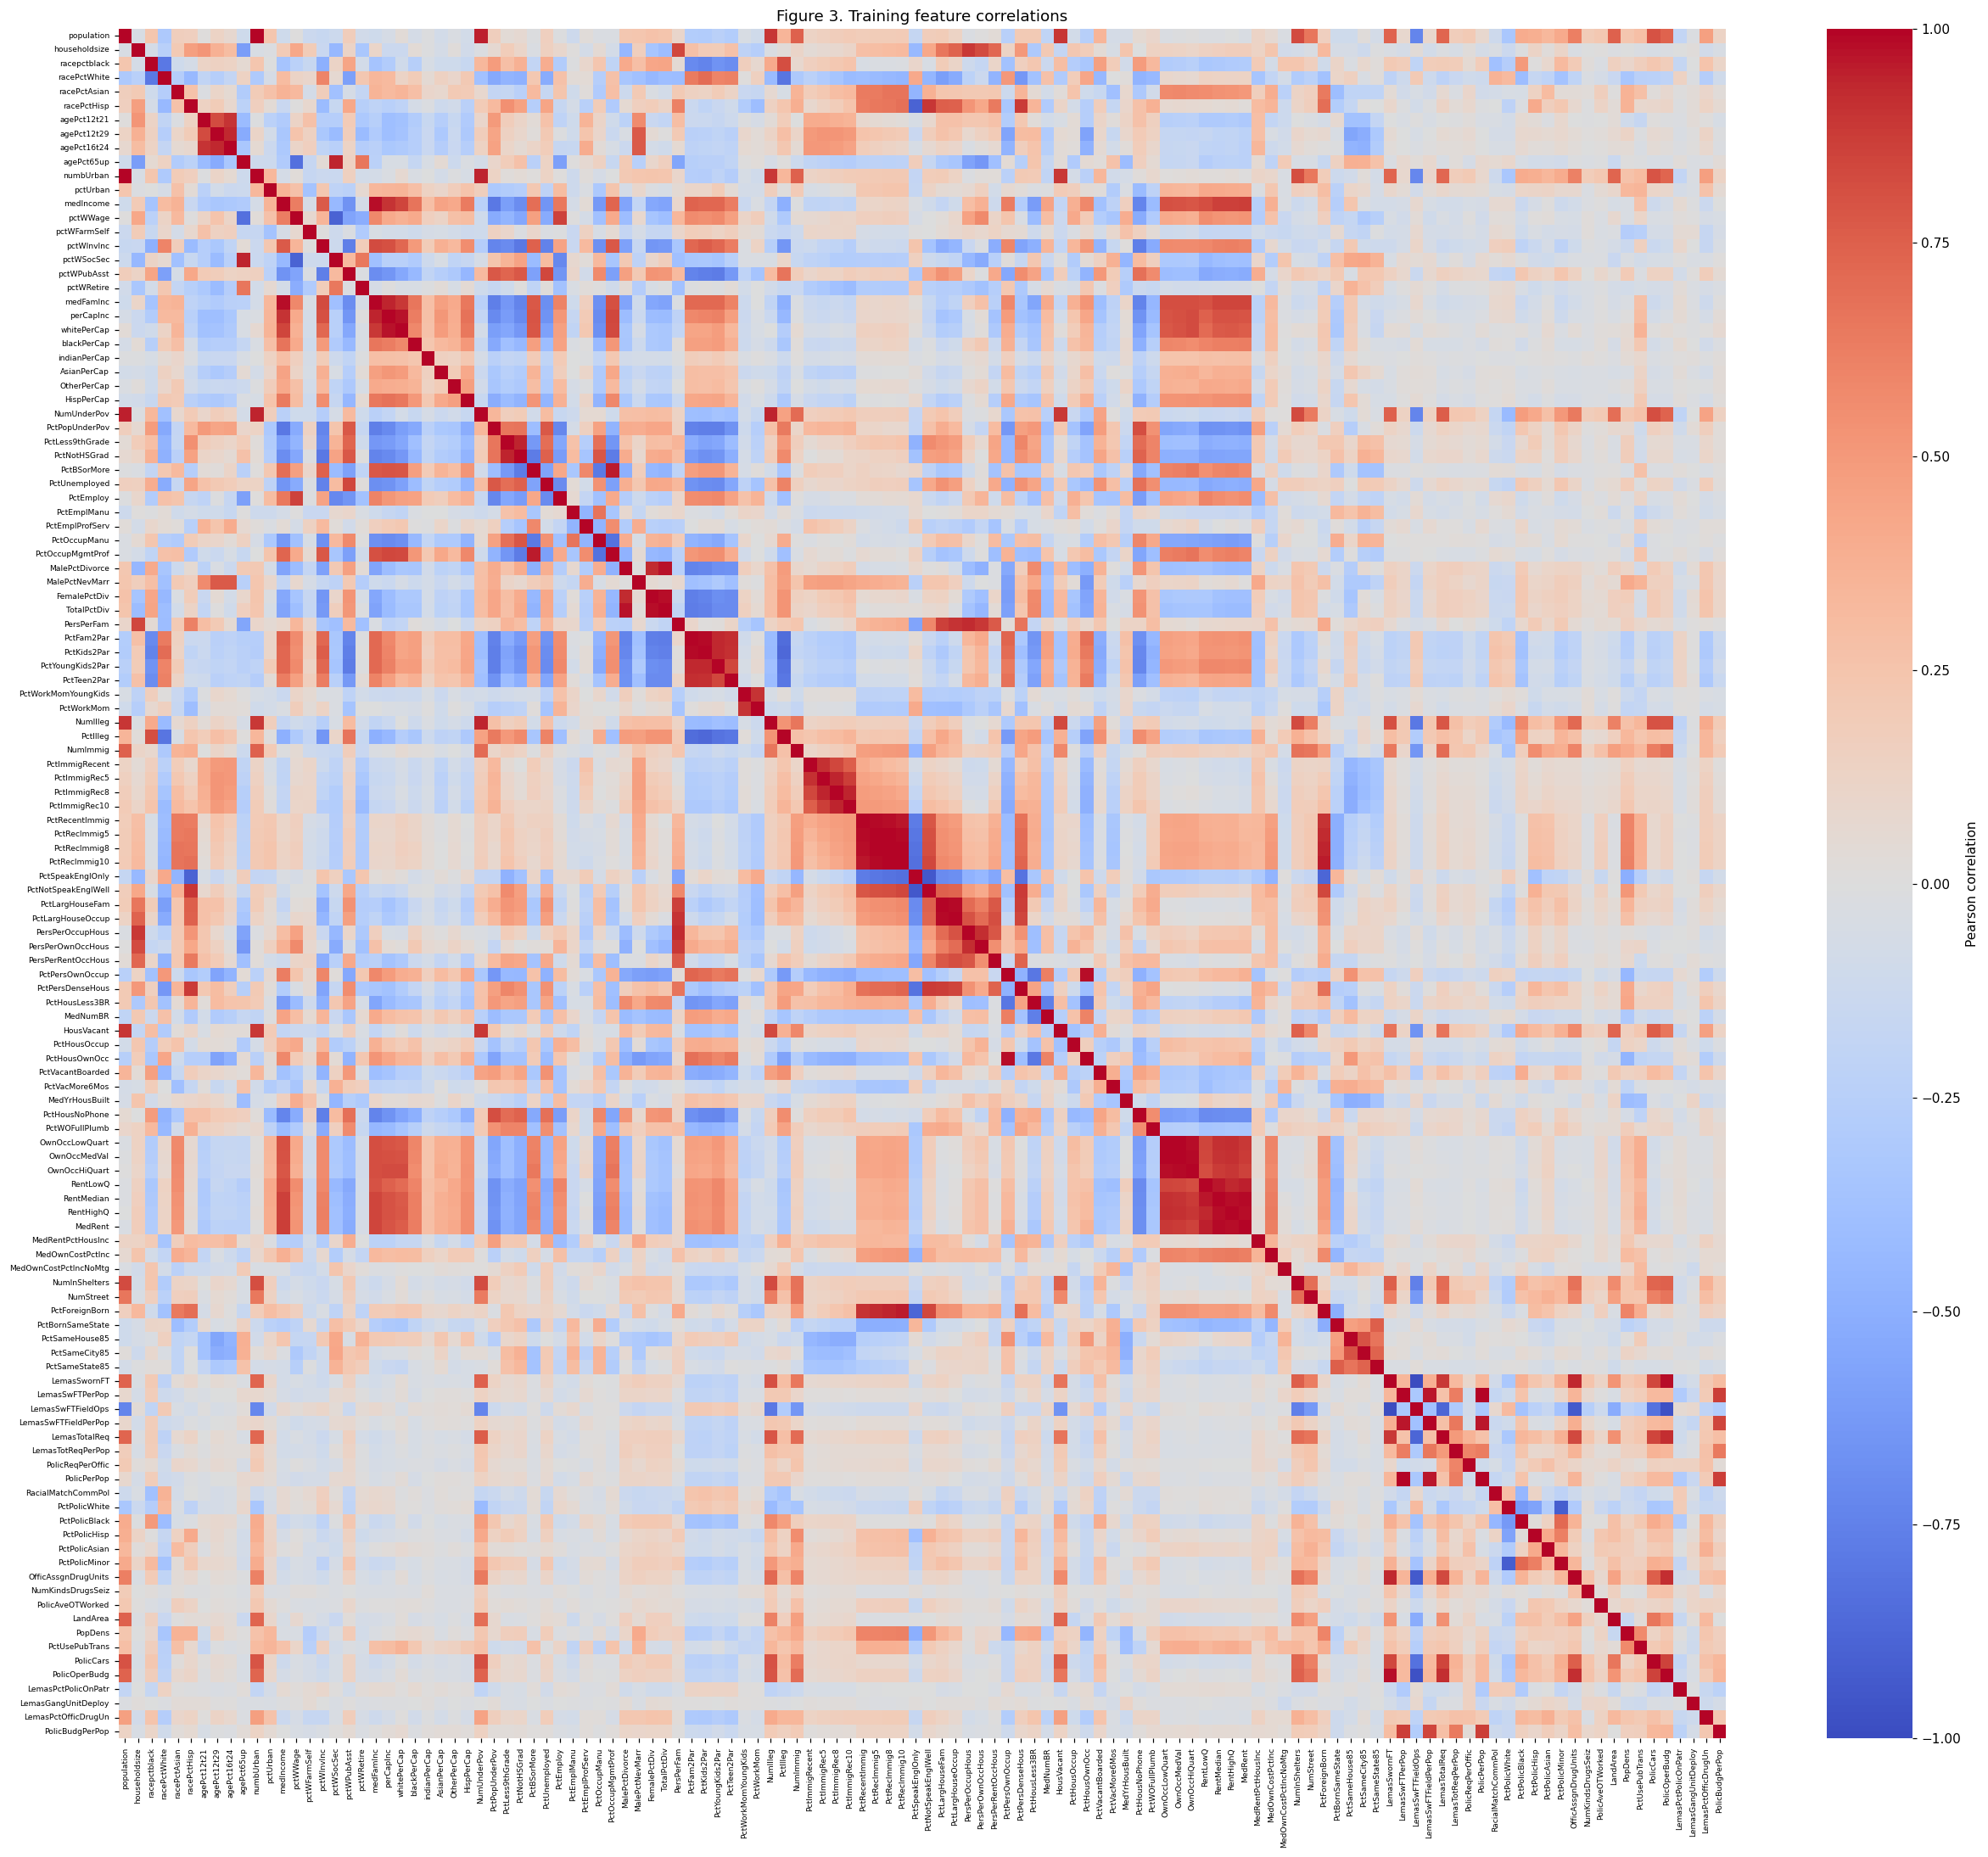

In [8]:
correlations = X_train_imputed.corr()
fig, ax = plt.subplots(figsize=(23, 20))
sns.heatmap(correlations, vmin=-1, vmax=1, center=0, cmap="coolwarm",
            xticklabels=True, yticklabels=True, ax=ax,
            cbar_kws={"label": "Pearson correlation"})
ax.tick_params(axis="both", labelsize=6)
ax.set_title("Figure 3. Training feature correlations")
fig.tight_layout()
fig.savefig(RESULT_DIR / "correlation_matrix.png", dpi=160, bbox_inches="tight")
plt.show()
correlations.to_csv(RESULT_DIR / "feature_correlations.csv")

## 2(d) Coefficient of variation

In [9]:
feature_means = X_train_imputed.mean()
feature_std = X_train_imputed.std(ddof=1)
feature_cv = feature_std / feature_means.replace(0, np.nan)
cv_table = pd.DataFrame({"Mean": feature_means, "Sample SD": feature_std, "CV": feature_cv})
cv_table = cv_table.sort_values("CV", ascending=False)
display(cv_table)
cv_table.to_csv(RESULT_DIR / "coefficient_of_variation.csv")

,Mean,Sample SD,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


## 2(e) Eleven highest-CV features

,Mean,Sample SD,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


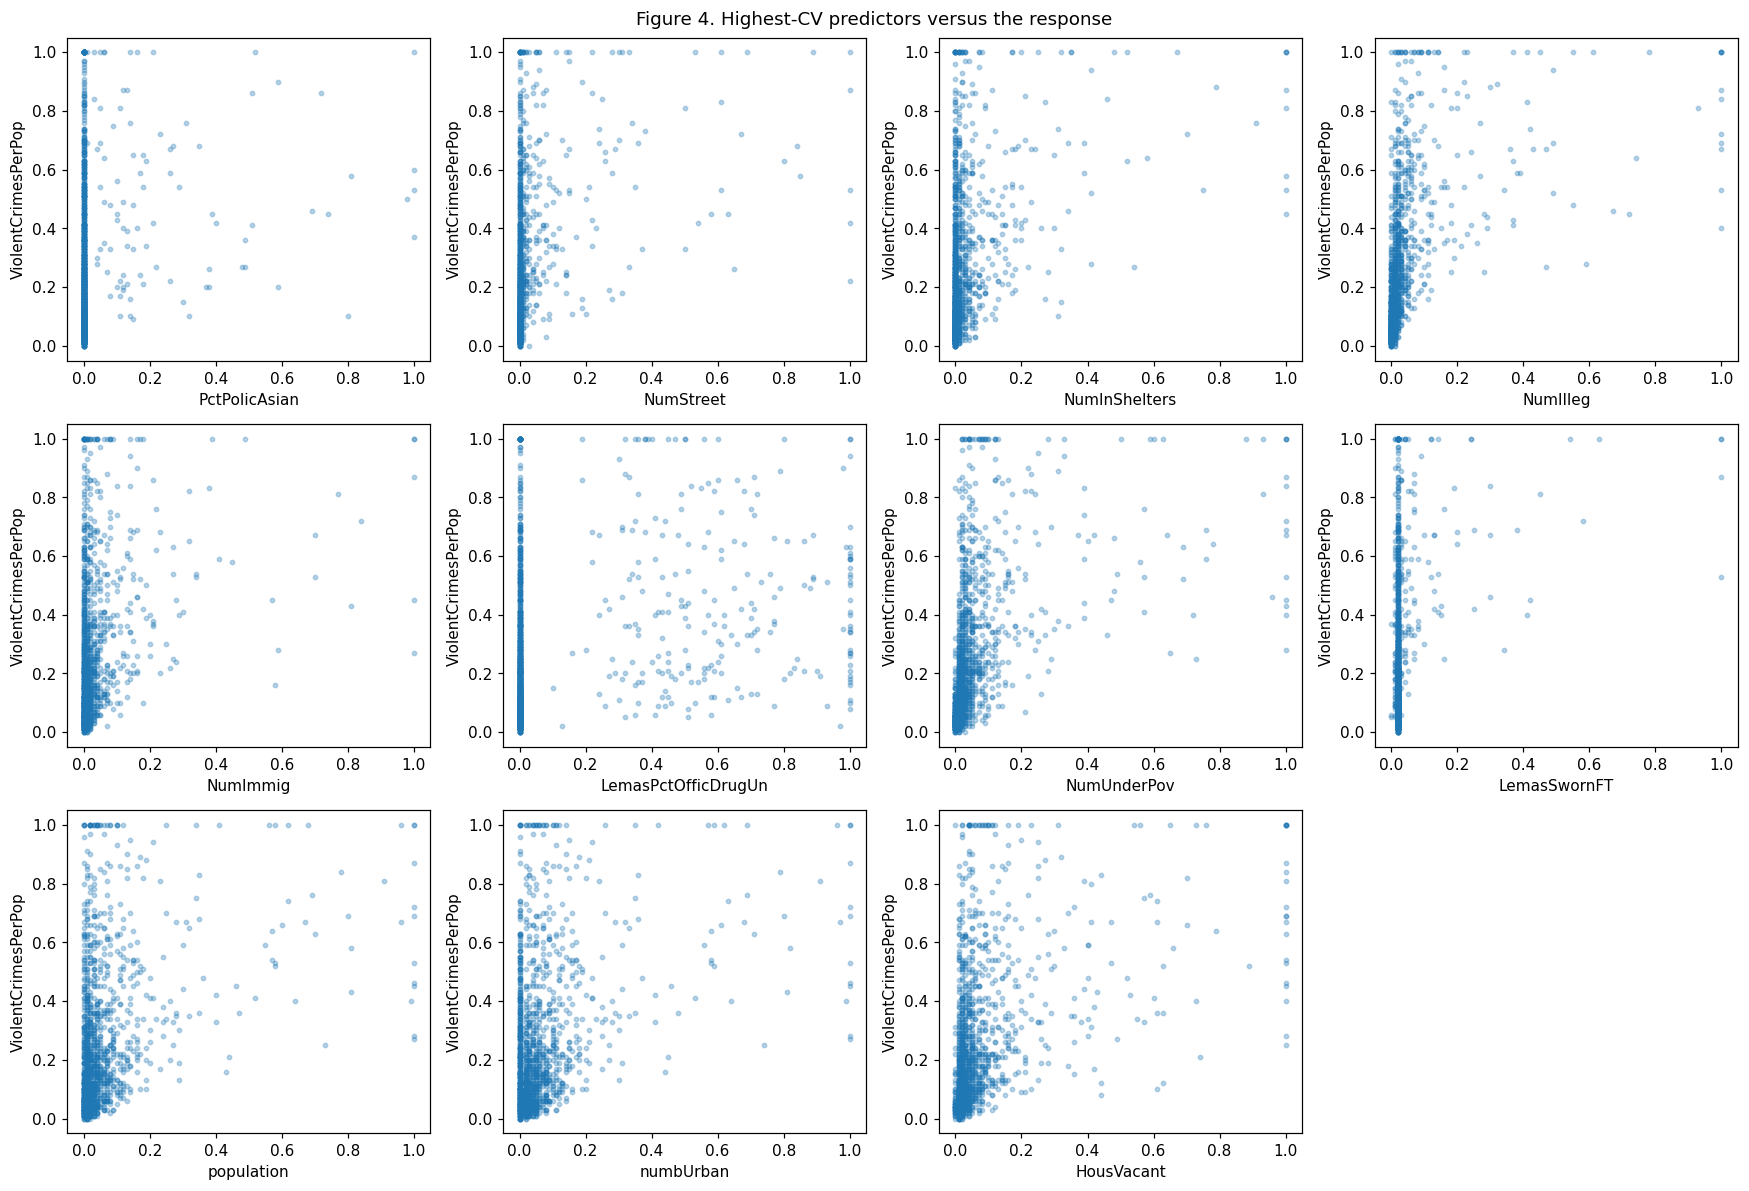

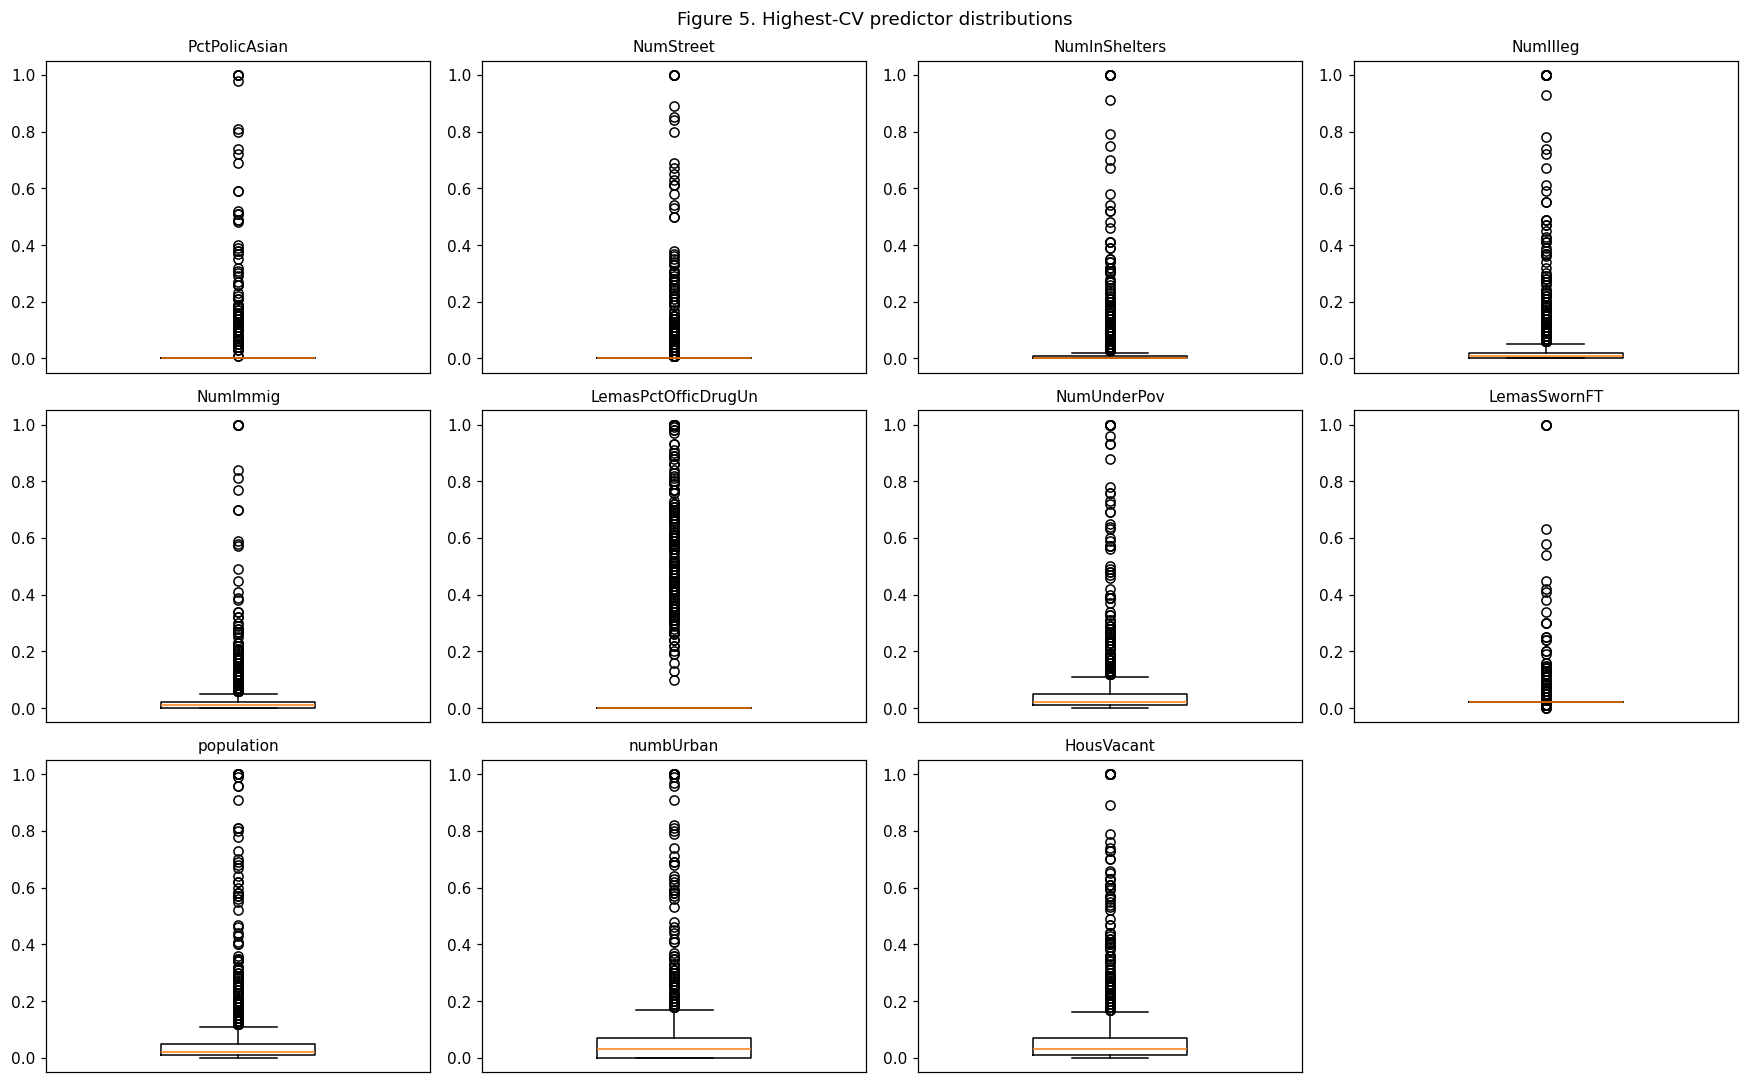

In [10]:
number_to_plot = int(np.sqrt(128))
top_features = cv_table["CV"].dropna().head(number_to_plot).index.tolist()
display(cv_table.loc[top_features])

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train_imputed[feature], y_train, s=8, alpha=0.3)
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")
for ax in list(axes.flat)[len(top_features):]:
    ax.set_visible(False)
fig.suptitle("Figure 4. Highest-CV predictors versus the response")
fig.tight_layout()
fig.savefig(RESULT_DIR / "top_cv_scatter.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, feature in zip(axes.flat, top_features):
    ax.boxplot(X_train_imputed[feature], widths=0.4)
    ax.set_title(feature, fontsize=10)
    ax.set_xticks([])
for ax in list(axes.flat)[len(top_features):]:
    ax.set_visible(False)
fig.suptitle("Figure 5. Highest-CV predictor distributions")
fig.tight_layout()
fig.savefig(RESULT_DIR / "top_cv_boxplots.png", bbox_inches="tight")
plt.show()

No. The plots can show a possible relationship, but they don't tell us whether a feature is statistically significant or how the other predictors affect that relationship.

## 2(f) Least-squares regression

I used MSE as the test error. For the models below, I chose parameters using the lowest average validation MSE across five shuffled training folds, with seed 552.

In [11]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train))
model_scores = []
test_predictions = pd.DataFrame({"Actual": y_test})

def evaluate_regression(name, model, cv_mse=np.nan):
    predictions = model.predict(X_test)
    row = {
        "Model": name, "CV MSE": cv_mse,
        "Test MSE": mean_squared_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions)
    }
    model_scores.append(row)
    test_predictions[name] = predictions
    display(pd.DataFrame([row]).set_index("Model"))

def tune_model(pipeline, parameter_grid, filename):
    search = GridSearchCV(
        pipeline, parameter_grid, scoring="neg_mean_squared_error",
        cv=folds, n_jobs=1, refit=True, error_score="raise"
    )
    with threadpool_limits(limits=1):
        search.fit(X_train, y_train)
    results = pd.DataFrame(search.cv_results_)
    results["CV MSE"] = -results["mean_test_score"]
    results.to_csv(RESULT_DIR / filename, index=False)
    print("Selected parameters:", search.best_params_)
    print("Mean CV MSE:", -search.best_score_)
    return search

ols = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])
with threadpool_limits(limits=1):
    ols.fit(X_train, y_train)
evaluate_regression("OLS", ols)

,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
OLS,NaN,0.017966,0.134038,0.096265,0.622204


## 2(g) Ridge regression

In [12]:
ridge = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", Ridge())
])
ridge_search = tune_model(ridge, {"model__alpha": np.logspace(-4, 4, 41)}, "ridge_cv.csv")
evaluate_regression("Ridge", ridge_search.best_estimator_, -ridge_search.best_score_)

Selected parameters: {'model__alpha': 63.09573444801943}
Mean CV MSE: 0.01914143066702239


,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
Ridge,0.019141,0.01746,0.132137,0.094434,0.632842


Cross-validation chose lambda = 63.0957 for Ridge. Its test MSE is 0.017460.

## 2(h) LASSO with and without standardization

In [13]:
lasso_grid = {"model__alpha": np.logspace(-5, 0, 41)}
lasso_raw = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", Lasso(max_iter=100000, tol=1e-6))
])
lasso_scaled = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", Lasso(max_iter=100000, tol=1e-6))
])
lasso_raw_search = tune_model(lasso_raw, lasso_grid, "lasso_raw_cv.csv")
lasso_scaled_search = tune_model(lasso_scaled, lasso_grid, "lasso_scaled_cv.csv")

for name, search in [("LASSO raw", lasso_raw_search), ("LASSO standardized", lasso_scaled_search)]:
    evaluate_regression(name, search.best_estimator_, -search.best_score_)
    coefficients = pd.Series(search.best_estimator_.named_steps["model"].coef_, index=X.columns)
    selected = coefficients[coefficients != 0]
    print(name, "selected variables:", len(selected))
    display(selected.to_frame("Coefficient"))
    coefficients.to_csv(RESULT_DIR / (name.replace(" ", "_") + "_coefficients.csv"))

Selected parameters: {'model__alpha': 0.0001}
Mean CV MSE: 0.018990937799933803


Selected parameters: {'model__alpha': 0.0005623413251903491}
Mean CV MSE: 0.019096323574296095


,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
LASSO raw,0.018991,0.017658,0.132883,0.09466,0.628689


LASSO raw selected variables: 75


,Coefficient
racepctblack,0.268807
racePctAsian,-0.017231
agePct12t21,0.074721
agePct12t29,-0.291055
agePct65up,0.002000
pctUrban,0.041249
pctWWage,-0.092275
pctWFarmSelf,0.029091
pctWInvInc,-0.111368
pctWSocSec,0.060713


,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
LASSO standardized,0.019096,0.017748,0.133222,0.094891,0.626791


LASSO standardized selected variables: 75


,Coefficient
racepctblack,0.068267
racePctAsian,-0.002344
agePct12t21,0.013794
agePct12t29,-0.046064
pctUrban,0.017402
pctWWage,-0.015348
pctWFarmSelf,0.005251
pctWInvInc,-0.022757
pctWSocSec,0.010992
pctWPubAsst,0.008815


Without standardization, LASSO chose alpha = 0.0001 and kept 75 variables, with a test MSE of 0.017658. After standardization, it chose alpha = 0.000562341 and also kept 75 variables, but the test MSE was 0.017748. So the version without standardization did slightly better on this test set.

## 2(i) Principal component regression

Selected parameters: {'pca__n_components': 93}
Mean CV MSE: 0.01944865310695159


,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
PCR,0.019449,0.018264,0.135145,0.097124,0.615937


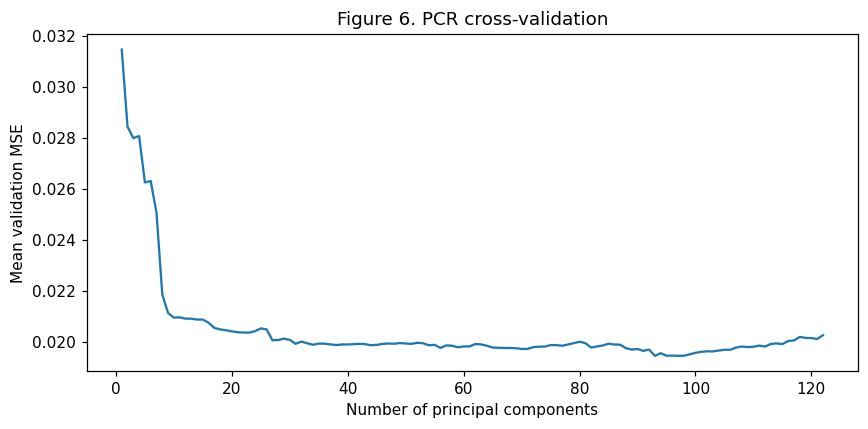

In [14]:
pcr = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("model", LinearRegression())
])
pcr_search = tune_model(pcr, {"pca__n_components": list(range(1, 123))}, "pcr_cv.csv")
evaluate_regression("PCR", pcr_search.best_estimator_, -pcr_search.best_score_)
pcr_results = pd.DataFrame(pcr_search.cv_results_)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pcr_results["param_pca__n_components"].astype(int), -pcr_results["mean_test_score"])
ax.set(xlabel="Number of principal components", ylabel="Mean validation MSE",
       title="Figure 6. PCR cross-validation")
fig.tight_layout()
fig.savefig(RESULT_DIR / "pcr_cv.png", bbox_inches="tight")
plt.show()

Cross-validation chose 93 principal components (M = 93), giving a test MSE of 0.018264.

## 2(j) L1-regularized gradient boosting

I used five-fold cross-validation to choose reg_alpha and kept the other XGBoost settings fixed. Here, reg_alpha controls the L1 penalty on leaf weights.

In [15]:
boosting = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("model", XGBRegressor(
        objective="reg:squarederror", booster="gbtree", tree_method="hist",
        n_estimators=500, max_depth=3, learning_rate=0.05,
        reg_lambda=0, subsample=1, colsample_bytree=1,
        random_state=SEED, n_jobs=1
    ))
])
boosting_search = tune_model(
    boosting, {"model__reg_alpha": [0, 0.001, 0.01, 0.1, 0.3, 1, 3, 10, 100]},
    "xgboost_cv.csv"
)
evaluate_regression("XGBoost L1", boosting_search.best_estimator_, -boosting_search.best_score_)

comparison = pd.DataFrame(model_scores).set_index("Model")
display(comparison)
comparison.to_csv(RESULT_DIR / "model_comparison.csv")
test_predictions.to_csv(RESULT_DIR / "test_predictions.csv", index_label="Original row index")
selected_parameters = {
    "Ridge alpha": ridge_search.best_params_["model__alpha"],
    "LASSO raw alpha": lasso_raw_search.best_params_["model__alpha"],
    "LASSO standardized alpha": lasso_scaled_search.best_params_["model__alpha"],
    "PCR M": pcr_search.best_params_["pca__n_components"],
    "XGBoost alpha": boosting_search.best_params_["model__reg_alpha"]
}
pd.Series(selected_parameters).to_csv(RESULT_DIR / "selected_parameters.csv")

Selected parameters: {'model__reg_alpha': 3}
Mean CV MSE: 0.01975012971092339


,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
XGBoost L1,0.01975,0.016215,0.127337,0.089782,0.659037


,CV MSE,Test MSE,Test RMSE,Test MAE,Test R2
Model,,,,,
OLS,NaN,0.017966,0.134038,0.096265,0.622204
Ridge,0.019141,0.017460,0.132137,0.094434,0.632842
LASSO raw,0.018991,0.017658,0.132883,0.094660,0.628689
LASSO standardized,0.019096,0.017748,0.133222,0.094891,0.626791
PCR,0.019449,0.018264,0.135145,0.097124,0.615937
XGBoost L1,0.019750,0.016215,0.127337,0.089782,0.659037


Cross-validation chose reg_alpha = 3. With this value, the test MSE is 0.016215.

## References

- Course handout: Homework 5; supplied diagnosis and communities data descriptions.
- [UCI Acute Inflammations](https://archive.ics.uci.edu/dataset/184/acute+inflammations).
- [UCI Communities and Crime](https://archive.ics.uci.edu/dataset/183/communities+and+crime).
- [Scikit-learn cost-complexity pruning](https://scikit-learn.org/1.3/auto_examples/tree/plot_cost_complexity_pruning.html).
- [Scikit-learn LASSO](https://scikit-learn.org/1.3/modules/generated/sklearn.linear_model.Lasso.html).
- [XGBoost parameters](https://xgboost.readthedocs.io/en/release_2.1.0/parameter.html).